# Лабораторная работа №3
## Дискретные системы

**Вариант: 5**

Работа выполнена в среде Python (NumPy / SciPy / Matplotlib).
Каждая функция, строящая график, дополнительно **сохраняет его в папку
проекта** `figures/`.

In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib
from scipy import signal as sps

rng = np.random.default_rng()
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

FIG_DIR = os.path.expanduser("~/University/TnAofDSP/lab3/source")
import os
os.makedirs(FIG_DIR, exist_ok=True)

def save_and_show(fig=None, name="figure"):
    '''Отображает график и сохраняет его как PNG
    в папку проекта figures/. Используется всеми построениями в работе.'''
    if fig is None:
        fig = plt.gcf()
    path = os.path.join(FIG_DIR, f"{name}.png")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"[график сохранён: {path}]")

In [2]:
def create_signal(SIGNAL_BEGIN, SIGNAL_END):
    assert SIGNAL_END > SIGNAL_BEGIN, "SIGNAL END MUST BE BIGGER THAN BEGIN"
        
    n = np.arange(SIGNAL_BEGIN, SIGNAL_END + 1)
    x = rng.random(SIGNAL_END - SIGNAL_BEGIN + 1)
    
    return n, x

def signal_mul(MULT_COEF, SIGNAL):
    
    return SIGNAL * MULT_COEF

def signal_sum(FIRST_SIGNAL, SECOND_SIGNAL):
    if len(FIRST_SIGNAL) >= len(SECOND_SIGNAL):
        long_sig, short_sig = FIRST_SIGNAL, SECOND_SIGNAL
    else:
        long_sig, short_sig = SECOND_SIGNAL, FIRST_SIGNAL
    
    result = long_sig
    
    for i in range(len(short_sig)):
        result[i] += short_sig[i]
        
    return result

def delay(SIGNAL, BACKWARD_STEP):
    if BACKWARD_STEP >= len(SIGNAL):
        return np.zeros(len(SIGNAL))
        
    if BACKWARD_STEP <= 0:
        return SIGNAL.copy()
        
    new_signal = np.zeros(len(SIGNAL))
    new_signal[BACKWARD_STEP:] = SIGNAL[:-BACKWARD_STEP]
    return new_signal

def get_AFC(SIGNAL, num_points: int = 512):
    n = np.arange(len(SIGNAL))
    exponent = np.exp(-1j * np.outer(np.linspace(0, np.pi, num_points), n))
    return np.abs(np.dot(exponent, SIGNAL))

---
# Часть 1. Общая

Возьмите систему $y(n) = 0,3 x(n) + 0,6 x(n − 1) + 0,3 x(n − 2) − 0,9 y(n − 2)$ и 

**а)** реализуйте её циклом с явным моделированием памяти по схеме.

In [3]:
class IIRfilter: 
    def __init__(self, b, a):

        self.b = np.array(b, dtype=float)
        self.a = np.array(a, dtype=float)
        
        self.A = len(b) - 1
        self.B = len(a) - 1 
        
        self.mem_x = np.zeros(self.A)
        self.mem_y = np.zeros(self.B)

    def process_sample(self, x): # Обрабатываем отдельный сэмпл
        y = self.b[0] * x
        
        if self.A > 0:
            y += np.dot(self.b[1:], self.mem_x)
            self.mem_x = np.roll(self.mem_x, 1)
            self.mem_x[0] = x
            
        if self.B > 0:
            y -= np.dot(self.a[1:], self.mem_y)
            self.mem_y = np.roll(self.mem_y, 1)
            self.mem_y[0] = y
            
        return y

    def process_signal(self, X): # Обрабатываем весь сигнал
        return np.array([self.process_sample(x) for x in X])

    def reset_memory(self):
        self.mem_x.fill(0)
        self.mem_y.fill(0)

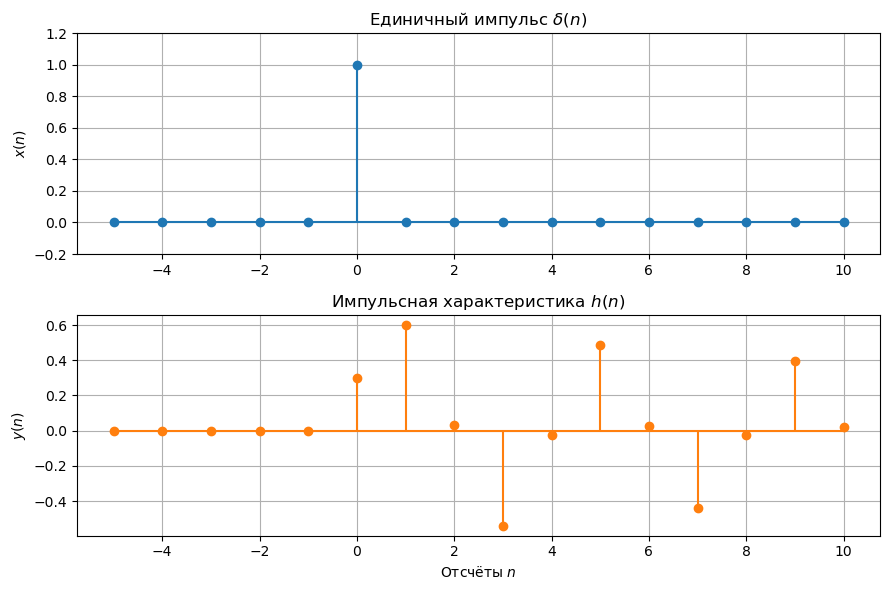

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/1_1_filter.png]


In [4]:
N = np.arange(16) - 5
X = np.zeros(len(N), dtype=float)
X[5] = 1.0

b = [0.3, 0.6, 0.3] # Входные данные
a = [1.0, 0.0, 0.9] # Выходные данные

flt = IIRfilter(b, a) # Используем свой фильтр с явным моделированием памяти
Y1 = flt.process_signal(X)

fig, (Xgraph, Ygraph) = plt.subplots(2, 1, figsize=(9, 6))

Xgraph.stem(N, X, basefmt="C0-")
Xgraph.set_ylabel("$x(n)$")
Xgraph.set_title("Единичный импульс $\delta(n)$")
Xgraph.set_ylim(-0.2, 1.2)

Ygraph.stem(N, Y1, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Ygraph.set_xlabel("Отсчёты $n$")
Ygraph.set_ylabel("$y(n)$")
Ygraph.set_title("Импульсная характеристика $h(n)$")

plt.tight_layout()
save_and_show(fig, name="1_1_filter")

**б)** реализуйте её используя ``filter(b, a, x)`` (в Python это ``sps.lfilter``)

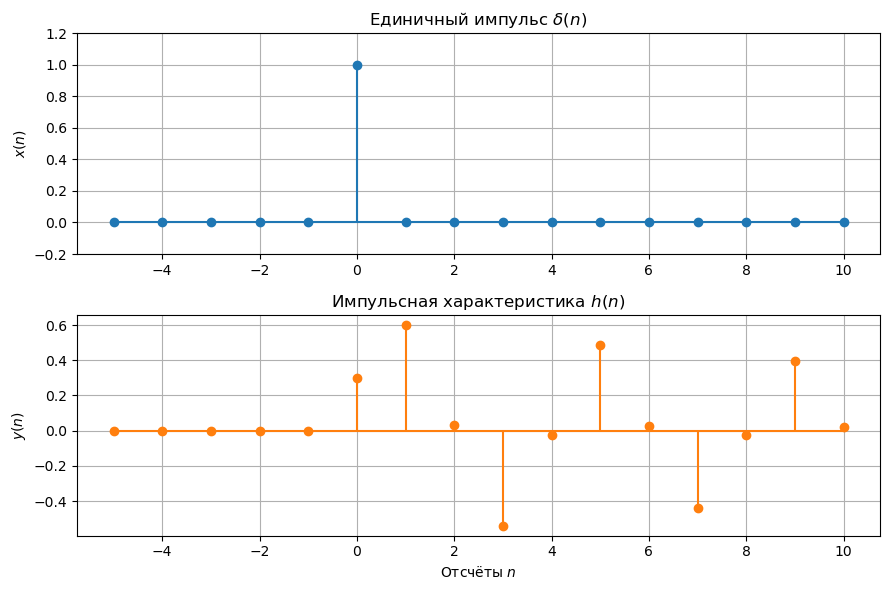

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/1_2_filter.png]


In [5]:
N = np.arange(16) - 5
X = np.zeros(len(N), dtype=float)
X[5] = 1.0

b = [0.3, 0.6, 0.3] # Входные данные
a = [1.0, 0.0, 0.9] # Выходные данные

Y2 = sps.lfilter(b,a,X)

fig, (Xgraph, Ygraph) = plt.subplots(2, 1, figsize=(9, 6))

Xgraph.stem(N, X, basefmt="C0-")
Xgraph.set_ylabel("$x(n)$")
Xgraph.set_title("Единичный импульс $\delta(n)$")
Xgraph.set_ylim(-0.2, 1.2)

Ygraph.stem(N, Y2, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Ygraph.set_xlabel("Отсчёты $n$")
Ygraph.set_ylabel("$y(n)$")
Ygraph.set_title("Импульсная характеристика $h(n)$")

plt.tight_layout()
save_and_show(fig, name="1_2_filter")

**в)** Подайте на обе реализации дельта-импульс и проверьте совпадение: ``max(abs(y1 ‐ y2))`` должно быть меньше $1e‐12$.

In [6]:
assert np.max(abs(Y1 - Y2)) < 1e-12, "False answer"
print("Выходные значения с нашего фильтра", Y1)
print("Выходные значения с scipy функции", Y2)
print("Максимальная разность по модулю", np.max(abs(Y1 - Y2)))

Выходные значения с нашего фильтра [ 0.        0.        0.        0.        0.        0.3       0.6
  0.03     -0.54     -0.027     0.486     0.0243   -0.4374   -0.02187
  0.39366   0.019683]
Выходные значения с scipy функции [ 0.        0.        0.        0.        0.        0.3       0.6
  0.03     -0.54     -0.027     0.486     0.0243   -0.4374   -0.02187
  0.39366   0.019683]
Максимальная разность по модулю 0.0


**г)** По полученной импульсной характеристике вычислите АЧХ прямым суммированием и сравните с результатом ``freqz(b, a, 512)``. Удвойте длину h(n) и убедитесь, что график перестал меняться

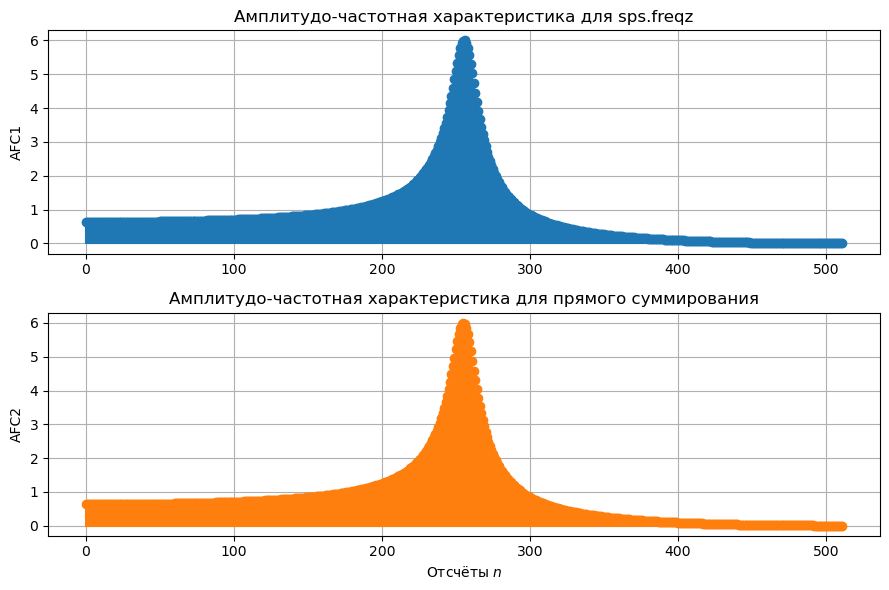

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/1_4_AFC.png]
Максимальная разность по модулю 0.1475855224602265


In [7]:
N = np.arange(1024)
X = np.zeros(len(N), dtype=float)
X[0] = 1.0

Y2 = sps.lfilter(b,a,X)

_, AFC1 = np.abs(sps.freqz(b, a, worN = 512))
AFC2 = get_AFC(Y2)

fig, (AFC1graph, AFC2graph) = plt.subplots(2, 1, figsize=(9, 6))

AFC1graph.stem(np.arange(len(AFC1)), AFC1, basefmt="C0-")
AFC1graph.set_ylabel("AFC1")
AFC1graph.set_title("Амплитудо-частотная характеристика для sps.freqz")

AFC2graph.stem(np.arange(len(AFC2)), AFC2, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
AFC2graph.set_xlabel("Отсчёты $n$")
AFC2graph.set_ylabel("AFC2")
AFC2graph.set_title("Амплитудо-частотная характеристика для прямого суммирования")

plt.tight_layout()
save_and_show(fig, name="1_4_AFC")

print("Максимальная разность по модулю", np.max(abs(AFC1 - AFC2)))

## 2. Свертка

Возьмите $h = [1, 2, 1]$ и произвольный сигнал $x$ длины 20

**a)** Вычислите свёртку тремя способами: ``conv(x,h)``, ``filter(h,1,x)`` и собственным
двойным циклом.

In [8]:
n, signal = create_signal(0,20)
h = [1,2,1]

y1 = np.convolve(signal, h)
y2 = sps.lfilter(h, 1, signal)
y3 = np.zeros(len(signal))

for i in range(len(signal)):
    for j in range(len(signal)):
        if 0 <= i - j < len(h):
            y3[i] += signal[j] * h[i - j]

print(y1[:21])
print(y2)
print(y3)

print('\n')
for i in range(len(signal)):
    print(abs(y2[i] - y1[i]), end = ' ')

print('\n')
for i in range(len(signal)):
    print(abs(y3[i] - y1[i]), end = ' ')

print('\n')
for i in range(len(signal)):
    print(abs(y2[i] - y3[i]), end = ' ')

[0.9269049  2.47441997 2.42584004 1.58483845 2.09689444 3.12538171
 2.79545145 1.79645244 1.59618566 2.04980214 2.54189003 1.96176891
 0.92998202 1.34716088 1.91514259 1.11474762 1.30683369 2.24639646
 2.30700176 3.06367038 3.5801561 ]
[0.9269049  2.47441997 2.42584004 1.58483845 2.09689444 3.12538171
 2.79545145 1.79645244 1.59618566 2.04980214 2.54189003 1.96176891
 0.92998202 1.34716088 1.91514259 1.11474762 1.30683369 2.24639646
 2.30700176 3.06367038 3.5801561 ]
[0.9269049  2.47441997 2.42584004 1.58483845 2.09689444 3.12538171
 2.79545145 1.79645244 1.59618566 2.04980214 2.54189003 1.96176891
 0.92998202 1.34716088 1.91514259 1.11474762 1.30683369 2.24639646
 2.30700176 3.06367038 3.5801561 ]


0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 

0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 

0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 

**б)** Объясните, почему длины результатов различаются, и укажите, какие именно отсчёты дает функция ``conv`` и не дает функция ``filter``.

Функция ``numpy.convolve``(1)(аналог ``conv`` из **MATLAB**) дает отличное от ``scipy.signal.lfilter``(2) (аналог ``filter`` из **MATLAB**) число отсчетов, потому что **(1)** считает **полную математическую свертку** в отличии от **(2)**, которая считает свертку только в рамках заданной функции.

## 3. Численная проверка линейности

**а)** Для нелинейной системы постройте $T\{x_1 +x_2\}, T\{x_1\}+T\{x_2\}$ и их разность.

Разность системы суммы и суммы систем:
 [0.         0.23919022 0.41559465 0.14799125 0.31967957 1.0373314
 0.57687426 0.43026973 0.0625388  0.02382481 0.21957892 0.8397228
 0.87549969 0.66274358 0.48875559 0.39033365 0.51329365 0.61606162
 0.5692348  0.55867412 0.03888914 0.04224533 0.67394784 1.31336072
 1.18367896 0.81258951 0.80491503 0.55658549 0.25606189 0.17801318
 0.38854158 0.51755708 0.33096626 0.46032845 0.828678   0.60338741
 0.33412079 0.52212361 0.31603489 0.70577036 0.49617881 0.14713246
 0.01072437 0.63368396 1.51497661 0.39309121 0.38424218 0.72105208
 0.29655508 0.83010611 0.0517161  0.02229691 0.52074597 0.70870277
 0.99441934 0.81850539 0.62948822 0.75764839 0.66045715 0.39663259
 0.09687745 0.44807489 0.44589247 0.62371889 1.0598573  0.42718777
 0.05438226 0.14032098 0.64153263 0.32368721 0.56653411 0.2599724
 0.53644638 0.58921525 0.80455253 0.64116178 0.5637921  0.70543112
 0.59808714 0.25693603 0.18049668 0.58500833 0.36053551 0.70897916
 0.71822298 0.70321748 0.

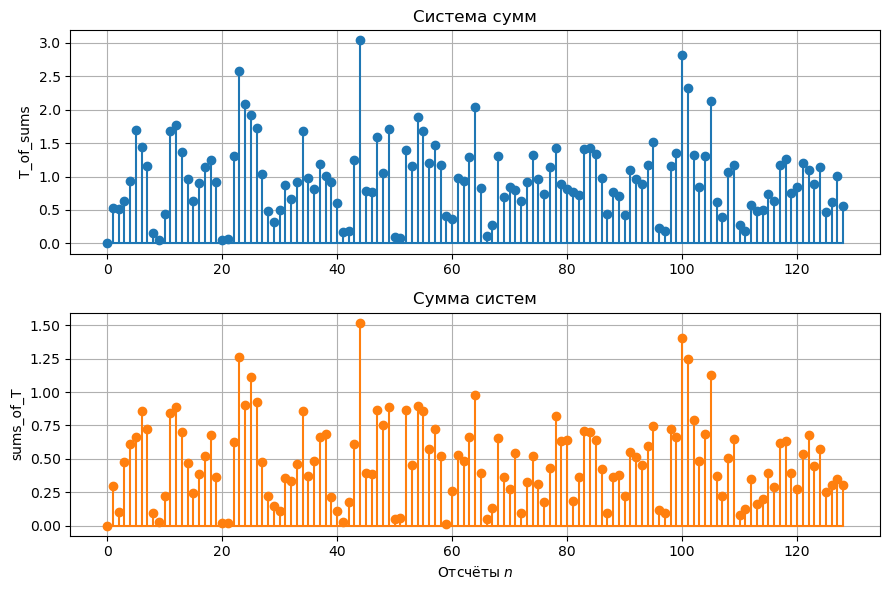

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/3_2_sub.png]


In [9]:
n1, s1 = create_signal(0,128)
n2, s2 = create_signal(0,128)

def T(s):
    s_delayed = delay(s, 1)
    return s * s_delayed
    
T_of_sums = T(s1 + s2)
sums_of_T = T(s1) + T(s2)

print("Разность системы суммы и суммы систем:\n", T_of_sums - sums_of_T)
print("Система нелинейна") if np.max(abs(T_of_sums - sums_of_T) > 1e-12) else print("Система линейна")

fig, (T_of_sums_graph, sums_of_T_graph) = plt.subplots(2, 1, figsize=(9, 6))

T_of_sums_graph.stem(n1, T_of_sums, basefmt="C0-")
T_of_sums_graph.set_ylabel("T_of_sums")
T_of_sums_graph.set_title("Система сумм")

sums_of_T_graph.stem(n1, sums_of_T, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
sums_of_T_graph.set_xlabel("Отсчёты $n$")
sums_of_T_graph.set_ylabel("sums_of_T")
sums_of_T_graph.set_title("Сумма систем")

plt.tight_layout()
save_and_show(fig, name="3_2_sub")

**б)** Cравните построенную разность с теоретическим выражением $x_1(n) x_2(n − 1) + x_2(n) x_1(n − 1)$.

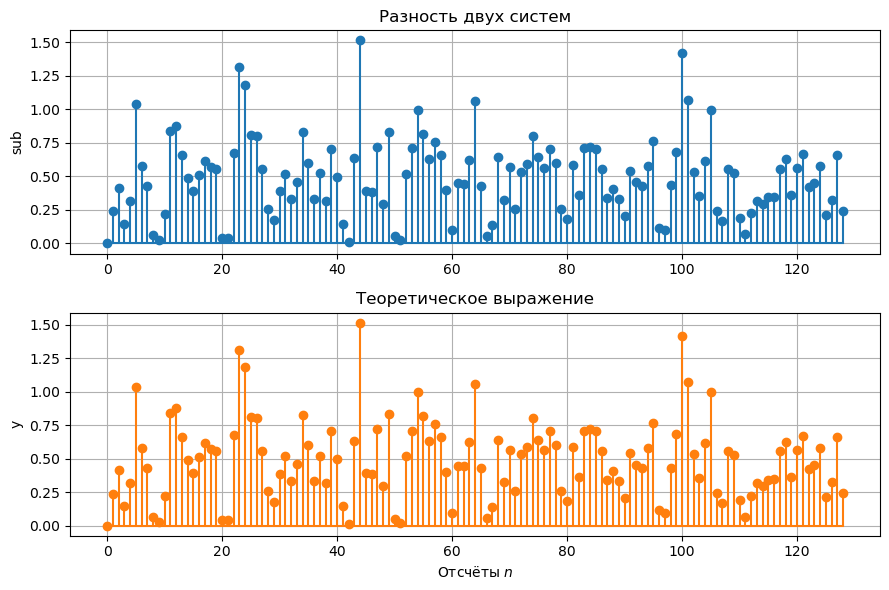

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/3_2_sub_and_y.png]


In [10]:
y = s1 * delay(s2, 1) + s2 * delay(s1, 1)

fig, (sub_graph, y_graph) = plt.subplots(2, 1, figsize=(9, 6))

sub_graph.stem(n1, T_of_sums - sums_of_T, basefmt="C0-")
sub_graph.set_ylabel("sub")
sub_graph.set_title("Разность двух систем")

y_graph.stem(n1, y, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
y_graph.set_xlabel("Отсчёты $n$")
y_graph.set_ylabel("y")
y_graph.set_title("Теоретическое выражение")

plt.tight_layout()
save_and_show(fig, name="3_2_sub_and_y")

## 4. Устойчивость

Рассмотрите систему $y(n) = a y(n − 1) + x(n)$ при $a = 0,9$; $1,0$; $1,01$.

Мы можем представить систему как фильтр с параметрами ``b = [1]``, ``a = [1, -a]``. Воспользуемся уже ранее использованой функцией ``scipy.signal.lfilter``

**а)** Постройте импульсные характеристики на 500 отсчётах в обычном и логарифмическом масштабе по оси ординат.

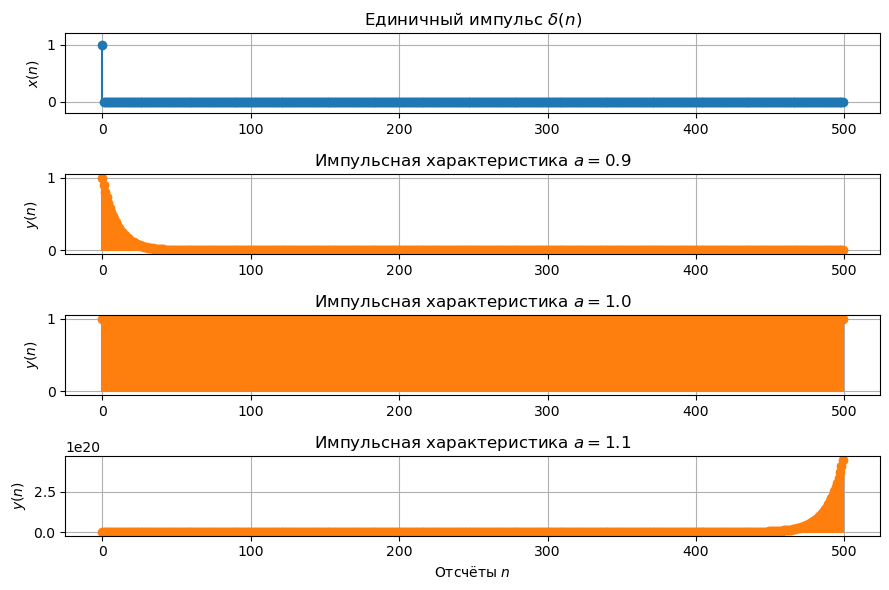

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/4_1_filter.png]


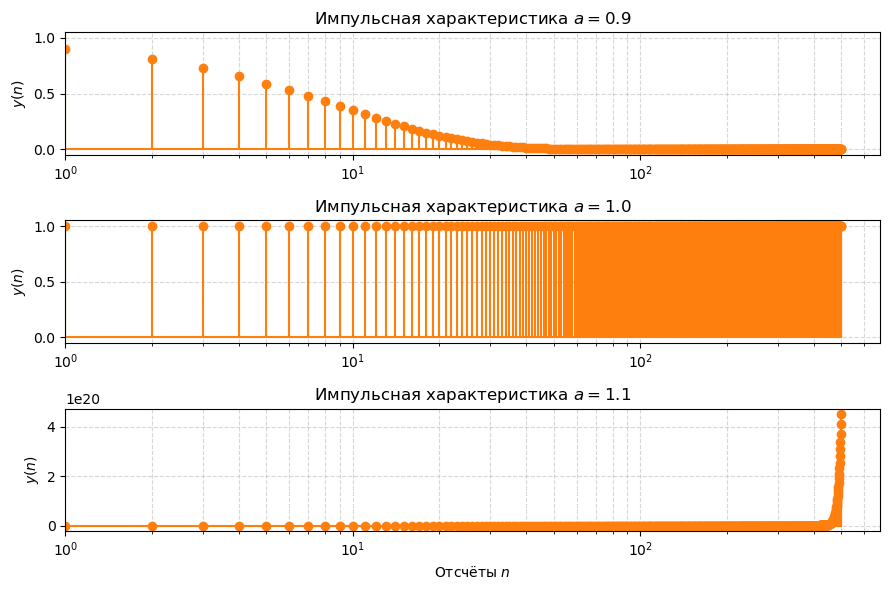

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/4_1_filter_log.png]


In [11]:
N = np.arange(500)
X = np.zeros(len(N), dtype=float)
X[0] = 1.0

b = [1.0] 
a1 = [1.0, -0.9]
a2 = [1.0, -1.0]
a3 = [1.0, -1.1]

y1 = sps.lfilter(b,a1,X)
y2 = sps.lfilter(b,a2,X)
y3 = sps.lfilter(b,a3,X)

fig, (Xgraph, Y1graph, Y2graph, Y3graph) = plt.subplots(4, 1, figsize=(9, 6))

Xgraph.stem(N, X, basefmt="C0-")
Xgraph.set_ylabel("$x(n)$")
Xgraph.set_title("Единичный импульс $\delta(n)$")
Xgraph.set_ylim(-0.2, 1.2)

Y1graph.stem(N, y1, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y1graph.set_ylabel("$y(n)$")
Y1graph.set_title("Импульсная характеристика $a = 0.9$")

Y2graph.stem(N, y2, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y2graph.set_ylabel("$y(n)$")
Y2graph.set_title("Импульсная характеристика $a = 1.0$")

Y3graph.stem(N, y3, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y3graph.set_ylabel("$y(n)$")
Y3graph.set_title("Импульсная характеристика $a = 1.1$")
Y3graph.set_xlabel("Отсчёты $n$")

plt.tight_layout()
save_and_show(fig, name="4_1_filter")

fig, (Y1graph, Y2graph, Y3graph) = plt.subplots(3, 1, figsize=(9, 6))

Y1graph.stem(N, y1, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y1graph.set_ylabel("$y(n)$")
Y1graph.set_title("Импульсная характеристика $a = 0.9$")
Y1graph.set_xscale('log')
Y1graph.set_xlim(left=1)
Y1graph.grid(True, which="both", linestyle="--", alpha=0.5)

Y2graph.stem(N, y2, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y2graph.set_ylabel("$y(n)$")
Y2graph.set_title("Импульсная характеристика $a = 1.0$")
Y2graph.set_xscale('log')
Y2graph.set_xlim(left=1)
Y2graph.grid(True, which="both", linestyle="--", alpha=0.5)

Y3graph.stem(N, y3, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y3graph.set_ylabel("$y(n)$")
Y3graph.set_title("Импульсная характеристика $a = 1.1$")
Y3graph.set_xlabel("Отсчёты $n$")
Y3graph.set_xscale('log')
Y3graph.set_xlim(left=1)
Y3graph.grid(True, which="both", linestyle="--", alpha=0.5)

plt.tight_layout()
save_and_show(fig, name="4_1_filter_log")

**б)** Для каждого **a** вычислите частичные суммы $\sum_{n=0}^{N} |h(n)|$ при N = 10, 100, 500 и
сведите в таблицу. Какие столбцы сходятся?

In [12]:
Ns = [10, 100, 500]
a_vec = [
    ("0.9", y1),
    ("1", y2),
    ("1.1", y3),
]

rows = []
for name, vector in a_vec:
    row = {"а = ": name}
    for N in Ns:
        row[f"N = {N}"] = round(float(np.sum(vector[:N])), 4)
    rows.append(row)

df = pd.DataFrame(rows).set_index("а = ")
df

,N = 10,N = 100,N = 500
а =,,,
0.9,6.5132,9.9997,1.000000e+01
1,10.0000,100.0000,5.000000e+02
1.1,15.9374,137796.1234,4.969842e+21


**в)** Подайте на все три системы единичную ступеньку. Что происходит с выходом
при $a = 1,0$ и почему этот случай — граничный?
    

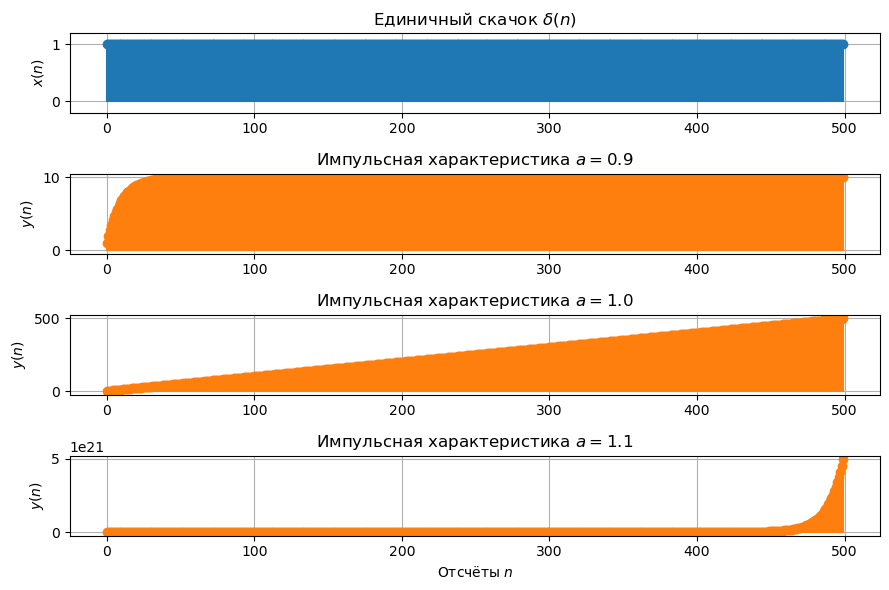

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/4_3_filter.png]


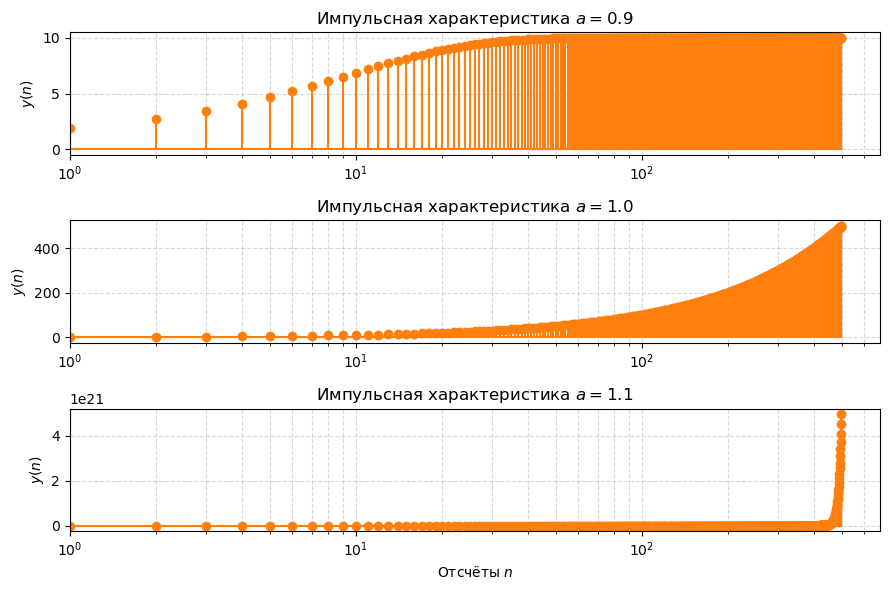

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/4_3_filter_log.png]


In [13]:
N = np.arange(500)
X = np.ones(len(N), dtype=float)

b = [1.0] 
a1 = [1.0, -0.9]
a2 = [1.0, -1.0]
a3 = [1.0, -1.1]

y1 = sps.lfilter(b,a1,X)
y2 = sps.lfilter(b,a2,X)
y3 = sps.lfilter(b,a3,X)

fig, (Xgraph, Y1graph, Y2graph, Y3graph) = plt.subplots(4, 1, figsize=(9, 6))

Xgraph.stem(N, X, basefmt="C0-")
Xgraph.set_ylabel("$x(n)$")
Xgraph.set_title("Единичный скачок $\delta(n)$")
Xgraph.set_ylim(-0.2, 1.2)

Y1graph.stem(N, y1, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y1graph.set_ylabel("$y(n)$")
Y1graph.set_title("Импульсная характеристика $a = 0.9$")

Y2graph.stem(N, y2, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y2graph.set_ylabel("$y(n)$")
Y2graph.set_title("Импульсная характеристика $a = 1.0$")

Y3graph.stem(N, y3, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y3graph.set_ylabel("$y(n)$")
Y3graph.set_title("Импульсная характеристика $a = 1.1$")
Y3graph.set_xlabel("Отсчёты $n$")

plt.tight_layout()
save_and_show(fig, name="4_3_filter")

fig, (Y1graph, Y2graph, Y3graph) = plt.subplots(3, 1, figsize=(9, 6))

Y1graph.stem(N, y1, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y1graph.set_ylabel("$y(n)$")
Y1graph.set_title("Импульсная характеристика $a = 0.9$")
Y1graph.set_xscale('log')
Y1graph.set_xlim(left=1)
Y1graph.grid(True, which="both", linestyle="--", alpha=0.5)

Y2graph.stem(N, y2, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y2graph.set_ylabel("$y(n)$")
Y2graph.set_title("Импульсная характеристика $a = 1.0$")
Y2graph.set_xscale('log')
Y2graph.set_xlim(left=1)
Y2graph.grid(True, which="both", linestyle="--", alpha=0.5)

Y3graph.stem(N, y3, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Y3graph.set_ylabel("$y(n)$")
Y3graph.set_title("Импульсная характеристика $a = 1.1$")
Y3graph.set_xlabel("Отсчёты $n$")
Y3graph.set_xscale('log')
Y3graph.set_xlim(left=1)
Y3graph.grid(True, which="both", linestyle="--", alpha=0.5)

plt.tight_layout()
save_and_show(fig, name="4_3_filter_log")

$a = 1$ - граничный случай в системе для единичного скачка по причине того, что при $a >= 1$ сист